# Notebook 2: Tiền Xử Lý & Tách Sọ Não (Skull Stripping)
**Căn cứ tài liệu:** `docs/KHUNG_NOI_DUNG_TONG_QUAT_DO_AN_XLAS.md`  
* **Quy trình chuẩn Bộ môn:** **Bước 2 — Tiền xử lý & Cải thiện chất lượng ảnh (Preprocessing & Skull Stripping)**  
* **Ánh xạ Báo cáo đồ án:** **Mục 4 — Tiền xử lý ảnh**  
* **Học phần:** Xử lý ảnh số (2026–2027) — Khoa CNTT — Trường ĐH Công Thương TP.HCM (HUIT)  
* **Nhóm thực hiện:** Hà Mạnh Trường (2045240326) & Huỳnh Tâm Trí (2045240315) — *Trường phụ trách chính*

---

## 1. Cơ sở lý thuyết DIP (Gonzalez & Woods Ch. 3, 5 & 9)
1. **Khử nhiễu Rician:** Áp dụng **Bilateral Filter** phi tuyến nhằm lọc nhiễu hạt y tế nhưng bảo toàn độ dốc cường độ tại ranh giới khối u:
   $$I_{\text{filtered}}(p) = \frac{1}{W_p} \sum_{q \in \Omega} I(q) \cdot g_{\sigma_s}(\|p - q\|) \cdot g_{\sigma_r}(|I(p) - I(q)|)$$
2. **Cân bằng tương phản:** Áp dụng **CLAHE** (Contrast Limited Adaptive Histogram Equalization) làm rõ cấu trúc mô mềm chất trắng / chất xám.
3. **Kỹ thuật Tách sọ não kinh điển (Skull Stripping):**
   * *Otsu Thresholding:* Nhị phân hóa tự động phân tách phần đầu khỏi nền đen dựa trên cực đại hóa phương sai giữa các lớp $\sigma_B^2(t)$.
   * *Morphological Opening:* Phép mở với phần tử cấu trúc dạng elip $B_{5 \times 5}$: $A \circ B = (A \ominus B) \oplus B$ cắt đứt các cầu nối mô giữa màng não và xương sọ.
   * *Largest Connected Component (LCC):* Trích xuất thành phần liên thông có diện tích lớn nhất (nhu mô não).
   * *Hole Filling:* Lấp đầy lỗ trống não thất bằng phép bù nhị phân và toán tử đóng hình thái học $A \bullet B = (A \oplus B) \ominus B$.
   * *Bitwise-AND:* Nhân mặt nạ não với ảnh gốc để thu được ảnh não sạch sọ hoàn hảo: $I_{\text{stripped}} = I \odot M_{\text{brain}}$.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt

REPO_ROOT = Path(".").resolve() if (Path(".").resolve() / "src").is_dir() else Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DATA_DIR = REPO_ROOT / "data" / "full"

from src.preprocessing.filters import apply_bilateral_filter, apply_clahe
from src.preprocessing.skull_strip import extract_brain_mask, strip_skull

print(f"Module tiền xử lý và tách sọ đã được nạp thành công. Data: {DATA_DIR}")

Module tiền xử lý và tách sọ đã được nạp thành công. Data: C:\Users\xpaga\Documents\xlas\data\full


## 2. Quy trình thực nghiệm: Thử nghiệm chi tiết từng bước tách sọ trên ca mẫu
Phân tích trực quan 6 giai đoạn xử lý từ ảnh MRI gốc đến ảnh sạch sọ trên ca lâm sàng tiêu biểu (TCGA_CS_6290_20000917_10):


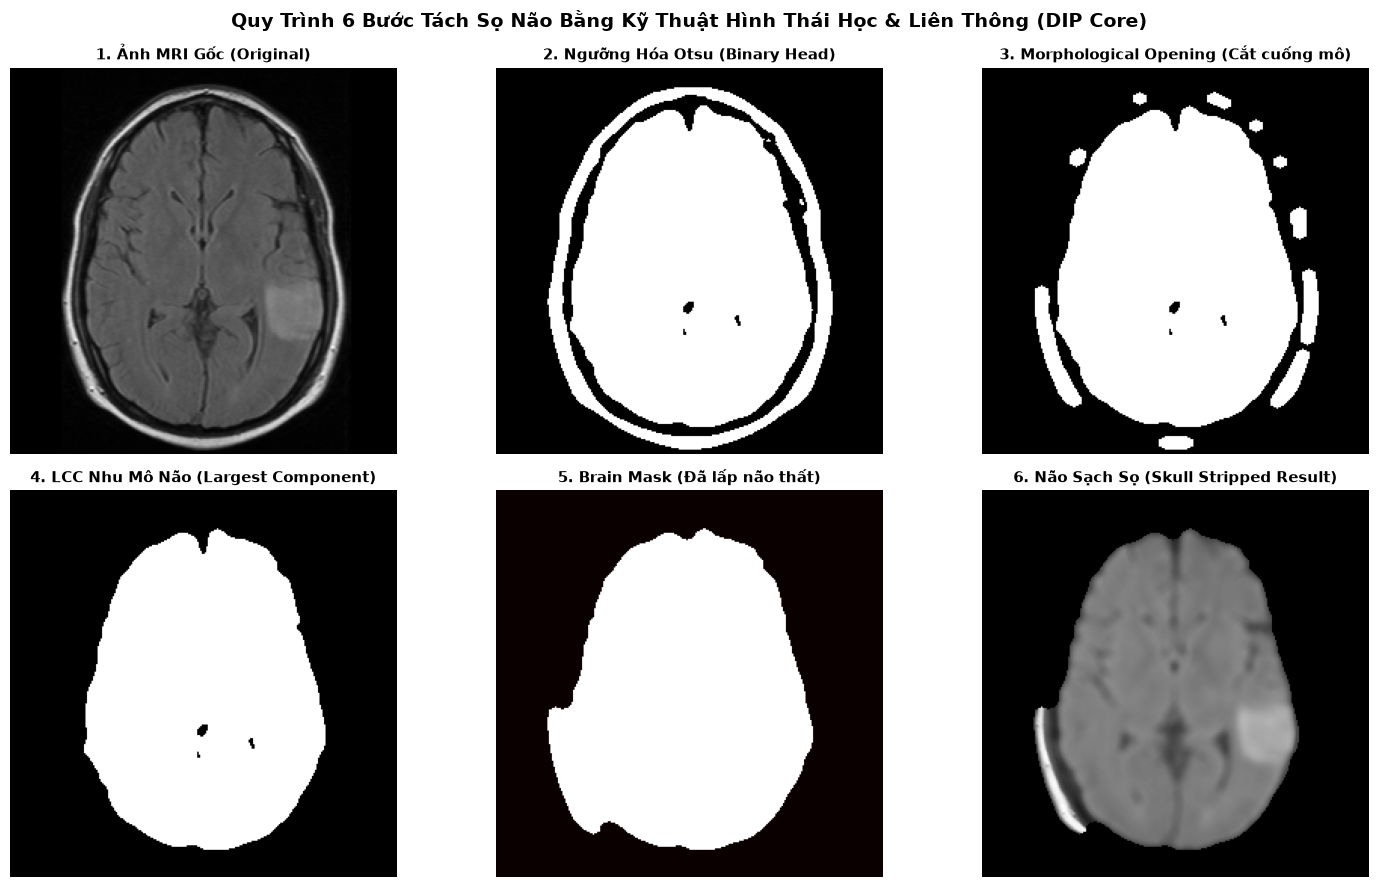

In [2]:
img_path = str(DATA_DIR / "images" / "TCGA_CS_6290_20000917_10.png")
orig_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

# 1. Khử nhiễu Bilateral
denoised = apply_bilateral_filter(orig_img, d=9, sigma_color=75.0, sigma_space=75.0)

# 2. Phân ngưỡng Otsu
_, otsu_bin = cv2.threshold(denoised, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Phép mở hình thái học (Opening với kernel elip 5x5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
opened = cv2.morphologyEx(otsu_bin, cv2.MORPH_OPEN, kernel, iterations=2)

# 4. Thành phần liên thông lớn nhất (LCC)
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(opened, connectivity=8)
largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
lcc_mask = np.zeros_like(orig_img)
lcc_mask[labels == largest_label] = 255

# 5. Lấp đầy lỗ hổng (Brain Mask hoàn chỉnh)
brain_mask = extract_brain_mask(denoised, kernel_size=5)

# 6. Não sạch sọ cuối cùng (Bitwise-AND)
stripped_brain, _ = strip_skull(denoised, brain_mask)

# Vẽ biểu đồ 6 bước
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
steps = [
    ("1. Ảnh MRI Gốc (Original)", orig_img, 'gray'),
    ("2. Ngưỡng Hóa Otsu (Binary Head)", otsu_bin, 'gray'),
    ("3. Morphological Opening (Cắt cuống mô)", opened, 'gray'),
    ("4. LCC Nhu Mô Não (Largest Component)", lcc_mask, 'gray'),
    ("5. Brain Mask (Đã lấp não thất)", brain_mask, 'hot'),
    ("6. Não Sạch Sọ (Skull Stripped Result)", stripped_brain, 'gray')
]

for i, (title, img_step, cmap) in enumerate(steps):
    r, c = i // 3, i % 3
    axes[r, c].imshow(img_step, cmap=cmap)
    axes[r, c].set_title(title, fontsize=11, fontweight='bold')
    axes[r, c].axis('off')

plt.suptitle("Quy Trình 6 Bước Tách Sọ Não Bằng Kỹ Thuật Hình Thái Học & Liên Thông (DIP Core)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 3. Ý nghĩa y khoa: Đánh giá khả năng tăng cường tương phản CLAHE
So sánh ảnh não sau tách sọ khi có và không áp dụng CLAHE:


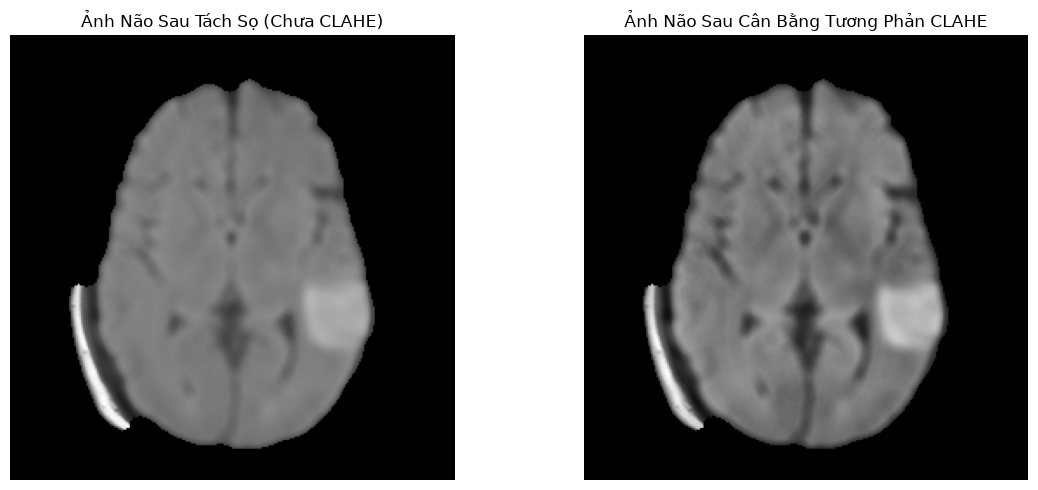

In [3]:
clahe_brain = apply_clahe(stripped_brain, clip_limit=2.0, tile_grid_size=(8, 8))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(stripped_brain, cmap='gray')
axes[0].set_title("Ảnh Não Sau Tách Sọ (Chưa CLAHE)", fontsize=12)
axes[0].axis('off')

axes[1].imshow(clahe_brain, cmap='gray')
axes[1].set_title("Ảnh Não Sau Cân Bằng Tương Phản CLAHE", fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()


## 4. Phân tích kết quả: Kiểm thử tính bền vững của tách sọ trên 4 ca lâm sàng tiêu biểu
Chứng minh thuật toán hoạt động ổn định trên nhiều dạng hình thái hộp sọ, kích thước u và đối chứng não lành (Healthy Control):


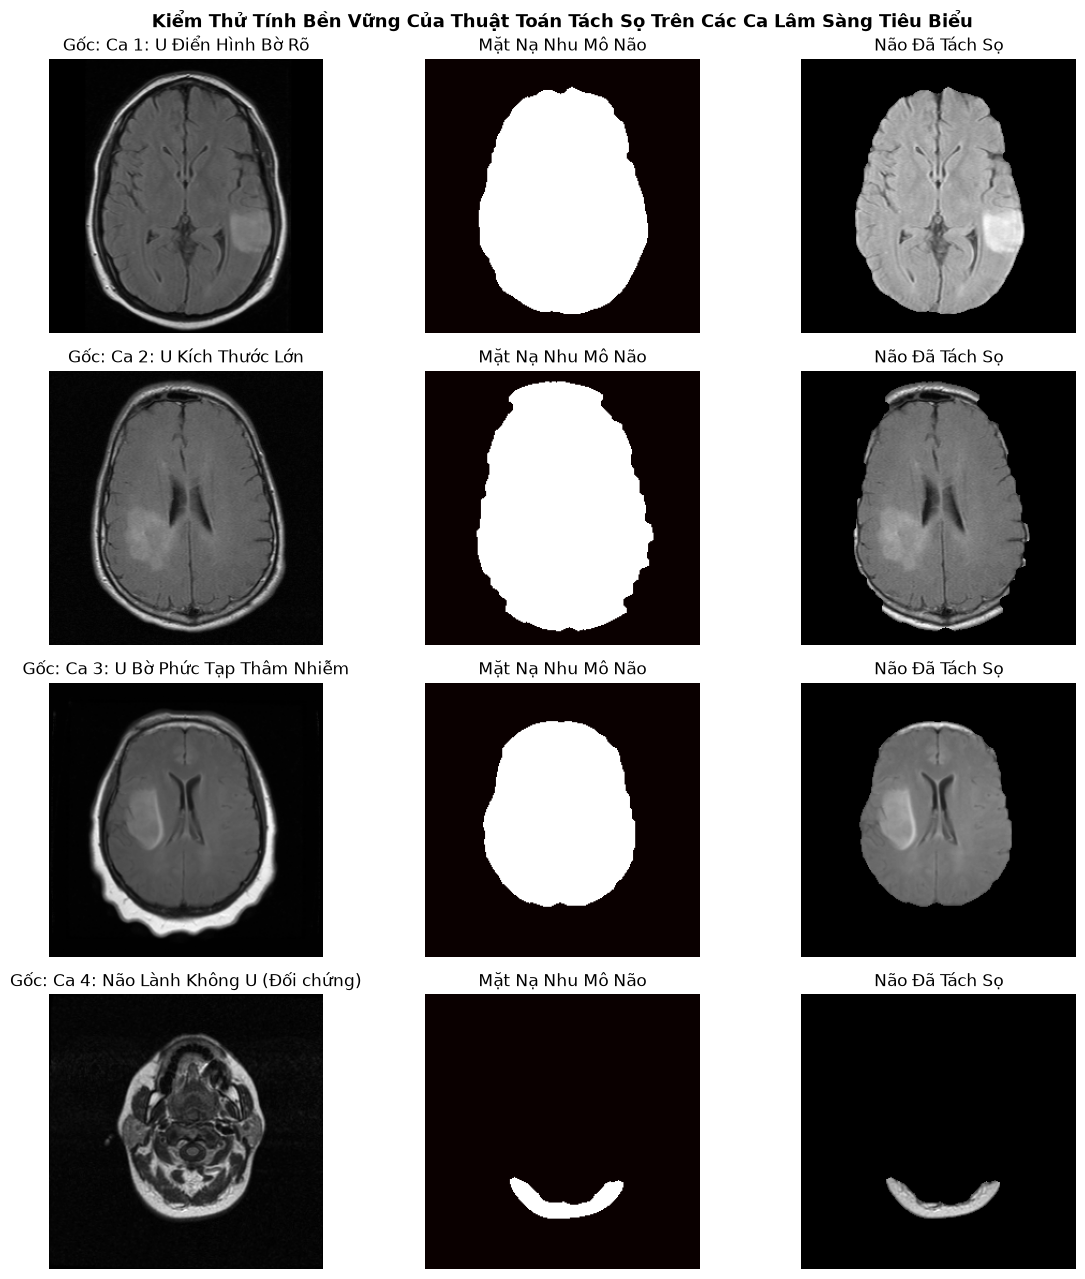

In [4]:
test_cases = [
    ("TCGA_CS_6290_20000917_10", "Ca 1: U Điển Hình Bờ Rõ"),
    ("TCGA_CS_6186_20000601_16", "Ca 2: U Kích Thước Lớn"),
    ("TCGA_CS_4942_19970222_12", "Ca 3: U Bờ Phức Tạp Thâm Nhiễm"),
    ("TCGA_DU_5851_19950428_2", "Ca 4: Não Lành Không U (Đối chứng)")
]

fig, axes = plt.subplots(4, 3, figsize=(12, 13))

for idx, (case_id, desc) in enumerate(test_cases):
    im_path = str(DATA_DIR / "images" / f"{case_id}.png")
    im = cv2.imread(im_path, cv2.IMREAD_GRAYSCALE)
    b_mask = extract_brain_mask(im)
    res_stripped, _ = strip_skull(im, b_mask)
    
    axes[idx, 0].imshow(im, cmap='gray')
    axes[idx, 0].set_title(f"Gốc: {desc}")
    axes[idx, 0].axis('off')
    
    axes[idx, 1].imshow(b_mask, cmap='hot')
    axes[idx, 1].set_title("Mặt Nạ Nhu Mô Não")
    axes[idx, 1].axis('off')
    
    axes[idx, 2].imshow(res_stripped, cmap='gray')
    axes[idx, 2].set_title("Não Đã Tách Sọ")
    axes[idx, 2].axis('off')

plt.suptitle("Kiểm Thử Tính Bền Vững Của Thuật Toán Tách Sọ Trên Các Ca Lâm Sàng Tiêu Biểu", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
